The code for getting the data from the frost API is based on the official MET guide (how to work with Frost using Python)
It was moderized using AI, which is stated in the AI transcript document, to more effectively build the dataframe.

In [37]:
import requests
import pandas as pd
import os
from dotenv import load_dotenv

# Laster inn .env-filen
load_dotenv()
client_id = os.getenv("FROST_CLIENT_ID")

def fetch_frost_data(sources, elements, referencetime):
    """this function will create a pandas dataframe from the frost API"""
    endpoint = 'https://frost.met.no/observations/v0.jsonld'
    parameters = {
        'sources': sources,
        'elements': elements,
        'referencetime': referencetime,
    }



    r = requests.get(endpoint, parameters, auth=(client_id, ''))

    if r.status_code == 200:
        data = r.json()['data']
    else:
        print(f"Feil: {r.status_code}")
        print(r.json()) # Skriver ut feilmelding fra API-et
        return None

# MODERNISERT OG RASKERE MÅTE Å BYGGE DATAFRAME PÅ:
    rows = []
    for item in data:
        ref_time = item['referenceTime']
        source_id = item['sourceId']
        for obs in item['observations']:
            # Kopierer felles metadata inn i hver observasjon
            obs['referenceTime'] = ref_time
            obs['sourceId'] = source_id
            rows.append(obs)

    df = pd.DataFrame(rows)

# Beholder kun relevante kolonner og rydder i tid
    columns = ['sourceId', 'referenceTime', 'elementId', 'value', 'unit', 'timeOffset']
    df = df[columns].copy()
    df['referenceTime'] = pd.to_datetime(df['referenceTime'])

# Sorter kronologisk (viktig for plotting og rullende gjennomsnitt senere!)
    df = df.sort_values('referenceTime').reset_index(drop=True)

    return df


df.head()


,sourceId,referenceTime,elementId,value,unit,timeOffset
0,SN17850:0,2025-01-01 00:00:00+00:00,mean(air_temperature P1D),-5.2,degC,PT0H
1,SN17850:0,2025-01-01 00:00:00+00:00,mean(air_temperature P1D),-2.8,degC,PT6H
2,SN17850:0,2025-01-02 00:00:00+00:00,mean(air_temperature P1D),-11.5,degC,PT0H
3,SN17850:0,2025-01-02 00:00:00+00:00,mean(air_temperature P1D),-7.2,degC,PT6H
4,SN17850:0,2025-01-03 00:00:00+00:00,mean(air_temperature P1D),-8.9,degC,PT0H


**task 1**



summary temperatures 2025:
mean     7.90
min    -16.10
max     24.50
std      7.53
Name: value, dtype: float64


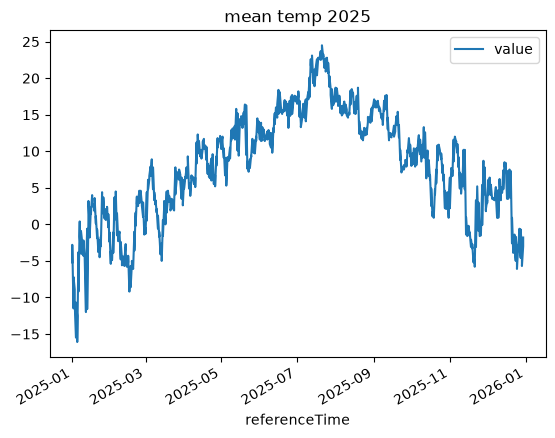

In [38]:
df_temp_2025 = fetch_frost_data(
    sources='SN17850', 
    elements='mean(air_temperature P1D)', 
    referencetime='2025-01-01/2025-12-31')

df.plot(x = 'referenceTime', y = 'value', title = 'mean temp 2025')

summary = df_temp_2025['value'].agg(['mean', 'min', 'max', 'std'])
summary = summary.round(2)

print("summary temperatures 2025:")
print(summary)